In [1]:
import os
# --- threshold_test parameters (set by run_all.py through the environment) ---
THRESH_TAG = os.environ.get('THRESH_TAG', 'm2.4')   # m2.4 = baseline cut of -2.4 dex
DATA_DIR = os.path.join('..', '..', 'data', f'thresh_{THRESH_TAG}')
OUT_ROOT = os.path.join('..', '..', 'outputs', f'thresh_{THRESH_TAG}')


In [2]:
import pandas as pd
import numpy as np

In [3]:
high_mass_satellite_df = pd.read_parquet(os.path.join(DATA_DIR, 'high_mass_satellite_df_annuli_revised.parquet'))
print('length of high- mass satellites df:', len(high_mass_satellite_df))

length of high- mass satellites df: 8675


In [4]:
high_mass_satellite_df

,subID,bin_radii,avg_s_mass,avg_SFR,avg_gas_mass,quenching_vector,gas_mass,s_mass,BHMass,class,veldisp,global_SFRs,BH_cumQM,BH_cumRM,Mhalo,overdens,bulge,Bfld,BH_AGN,GrNr
91,1.0,0.037018,10.065946,-1.977420,6.628361,0,5069.831055,55.879173,0.125518,1,333.89325,0.197048,9.718077e+07,6.904271e-310,38878.035156,8780.408392,0.508532,0.152681,9.718077e+07,0
92,1.0,0.111053,9.816378,-2.138036,6.690369,0,5069.831055,55.879173,0.125518,1,333.89325,0.197048,9.718077e+07,6.904271e-310,38878.035156,8780.408392,0.508532,0.152681,9.718077e+07,0
93,1.0,0.185088,9.498950,-2.488943,6.717174,0,5069.831055,55.879173,0.125518,1,333.89325,0.197048,9.718077e+07,6.904271e-310,38878.035156,8780.408392,0.508532,0.152681,9.718077e+07,0
94,1.0,0.259123,9.273945,-2.704103,6.806918,0,5069.831055,55.879173,0.125518,1,333.89325,0.197048,9.718077e+07,6.904271e-310,38878.035156,8780.408392,0.508532,0.152681,9.718077e+07,0
95,1.0,0.333158,9.124043,-2.386751,7.096273,0,5069.831055,55.879173,0.125518,1,333.89325,0.197048,9.718077e+07,6.904271e-310,38878.035156,8780.408392,0.508532,0.152681,9.718077e+07,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33561,476528.0,0.179965,9.485483,-2.459436,7.232764,0,0.000000,3.387989,0.010589,1,112.13295,0.018142,1.015537e+06,0.000000e+00,121.820320,6.780018,0.403195,0.133146,1.015537e+06,1335
33562,476528.0,0.539895,9.195900,-2.790333,6.889097,0,0.000000,3.387989,0.010589,1,112.13295,0.018142,1.015537e+06,0.000000e+00,121.820320,6.780018,0.403195,0.133146,1.015537e+06,1335
33563,476528.0,0.899825,8.818249,-3.192451,6.611662,1,0.000000,3.387989,0.010589,1,112.13295,0.018142,1.015537e+06,0.000000e+00,121.820320,6.780018,0.403195,0.133146,1.015537e+06,1335
33564,476528.0,1.259755,8.497334,-3.498477,6.271559,1,0.000000,3.387989,0.010589,1,112.13295,0.018142,1.015537e+06,0.000000e+00,121.820320,6.780018,0.403195,0.133146,1.015537e+06,1335


In [5]:
# # calculating star forming efficiency (SFE) and gas fraction 
# low_mass_satellite_df['SFE'] = 10**(low_mass_satellite_df['avg_SFR'] - low_mass_satellite_df['avg_gas_mass'])
# low_mass_satellite_df['f_gas'] = 10**(low_mass_satellite_df['avg_gas_mass'] - low_mass_satellite_df['avg_s_mass'])

In [6]:
# # remove the rows where the sfr_indicator is 0.0 -> implies artificially imposed minimum
# low_mass_satellite_df = low_mass_satellite_df[low_mass_satellite_df['sfr_indicator'] != 0.0]
# low_mass_satellite_df

In [7]:
# star forming quenching vector value = 0
high_mass_satellite_df = high_mass_satellite_df[high_mass_satellite_df['quenching_vector'] == 0]
high_mass_satellite_df

,subID,bin_radii,avg_s_mass,avg_SFR,avg_gas_mass,quenching_vector,gas_mass,s_mass,BHMass,class,veldisp,global_SFRs,BH_cumQM,BH_cumRM,Mhalo,overdens,bulge,Bfld,BH_AGN,GrNr
91,1.0,0.037018,10.065946,-1.977420,6.628361,0,5069.831055,55.879173,0.125518,1,333.893250,0.197048,9.718077e+07,6.904271e-310,38878.035156,8780.408392,0.508532,0.152681,9.718077e+07,0
92,1.0,0.111053,9.816378,-2.138036,6.690369,0,5069.831055,55.879173,0.125518,1,333.893250,0.197048,9.718077e+07,6.904271e-310,38878.035156,8780.408392,0.508532,0.152681,9.718077e+07,0
93,1.0,0.185088,9.498950,-2.488943,6.717174,0,5069.831055,55.879173,0.125518,1,333.893250,0.197048,9.718077e+07,6.904271e-310,38878.035156,8780.408392,0.508532,0.152681,9.718077e+07,0
94,1.0,0.259123,9.273945,-2.704103,6.806918,0,5069.831055,55.879173,0.125518,1,333.893250,0.197048,9.718077e+07,6.904271e-310,38878.035156,8780.408392,0.508532,0.152681,9.718077e+07,0
95,1.0,0.333158,9.124043,-2.386751,7.096273,0,5069.831055,55.879173,0.125518,1,333.893250,0.197048,9.718077e+07,6.904271e-310,38878.035156,8780.408392,0.508532,0.152681,9.718077e+07,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31452,462987.0,0.868261,8.582487,-1.080499,8.100421,0,0.000000,2.001361,0.003254,1,83.934608,2.233273,7.552357e+01,0.000000e+00,129.809052,0.046284,-1.015946,0.104524,7.552357e+01,1113
31453,462987.0,1.215566,8.400651,-1.433384,7.964696,0,0.000000,2.001361,0.003254,1,83.934608,2.233273,7.552357e+01,0.000000e+00,129.809052,0.046284,-1.015946,0.104524,7.552357e+01,1113
31454,462987.0,1.562870,8.203698,-1.477430,7.840324,0,0.000000,2.001361,0.003254,1,83.934608,2.233273,7.552357e+01,0.000000e+00,129.809052,0.046284,-1.015946,0.104524,7.552357e+01,1113
33561,476528.0,0.179965,9.485483,-2.459436,7.232764,0,0.000000,3.387989,0.010589,1,112.132950,0.018142,1.015537e+06,0.000000e+00,121.820320,6.780018,0.403195,0.133146,1.015537e+06,1335


In [8]:
high_mass_satellite_df.shape

(5716, 20)

In [9]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import RobustScaler

# 'BHMass', 'BHCum_QM', 'Mhalo', 'overdens', and 'bulge' are the features wer are testing
high_mass_satellite_df = high_mass_satellite_df.drop(columns=["class", "BH_cumQM", "BH_cumRM", "global_SFRs", "gas_mass","avg_gas_mass", "quenching_vector", "Bfld", "veldisp", "BH_AGN", "bulge"])

<Axes: >

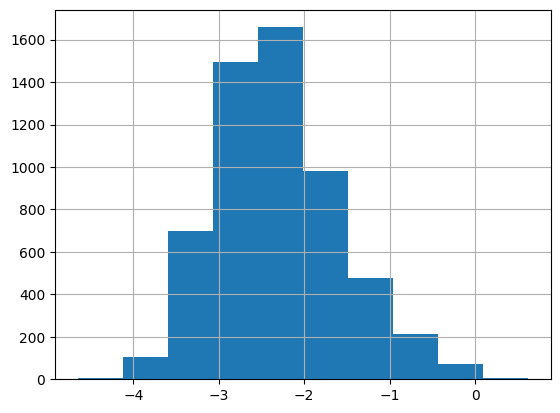

In [10]:
high_mass_satellite_df['avg_SFR'].hist()

In [11]:
# this indicates that there are more instances of the delta rate on the left

In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import RobustScaler
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold

feature_importances_list = []
feature_names = None
test_mses = []
train_mses = []


for seed in range(10):
    # split halos (GrNr) into 50% training and 50% testing, so galaxies from the same halo never span train and test
    unique_halos = np.unique(high_mass_satellite_df['GrNr'])
    train_galaxies, test_galaxies = train_test_split(unique_halos, test_size=0.5, random_state=seed)

    # assign galaxies based on halo split
    train_data = high_mass_satellite_df[high_mass_satellite_df['GrNr'].isin(train_galaxies)]
    test_data = high_mass_satellite_df[high_mass_satellite_df['GrNr'].isin(test_galaxies)]

    X_train, y_train = train_data.drop(columns=['avg_SFR', 'subID', 'GrNr']), train_data['avg_SFR']
    X_test, y_test = test_data.drop(columns=['avg_SFR', 'subID', 'GrNr']), test_data['avg_SFR']
    
    
    if feature_names is None:
        feature_names = X_train.columns.tolist()

    scaler = RobustScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    groups_train = train_data['GrNr']
    cv = GroupKFold(n_splits=5)

    # XGBoost Regressor
    xgb_regressor = XGBRegressor(random_state=seed, n_jobs=-1)

    param_grid = {
    'n_estimators': [100,150,200,250],
    'max_depth': [1],
    'learning_rate': [0.01],
    'subsample': [0.5,0.6, 0.7],
    'colsample_bytree': [1.0],
    'min_child_weight': [20, 25, 30],
    'alpha': [8, 12, 15],
    'lambda': [15, 20, 25]#, 30, 35]
    }
    """
    param_grid = {
    'n_estimators': [600],
    'max_depth': [2],
    'learning_rate': [0.006],
    'subsample': [0.6, 0.7, 0.8],
    'colsample_bytree': [1.0],
    'min_child_weight': [30, 40, 50],
    'alpha': [3, 4, 5],
    'lambda': [2, 3, 4],
    }
    """

    grid_search = GridSearchCV(
    estimator=xgb_regressor, 
    param_grid=param_grid, 
    cv=cv, 
    scoring='neg_mean_squared_error',
    n_jobs=-1, 
    verbose=2
    )

    grid_search.fit(X_train_scaled, y_train, groups=groups_train)

    best_xg_regressor = grid_search.best_estimator_
    print(f"Best parameters for seed {seed+1}: {grid_search.best_params_}")

    best_xg_regressor.fit(X_train_scaled, y_train)
    
    y_train_pred = best_xg_regressor.predict(X_train_scaled)
    y_test_pred = best_xg_regressor.predict(X_test_scaled)
    
    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)
    print(f"Run {seed+1}: Train MSE = {train_mse:.4f}, Test MSE = {test_mse:.4f}, Gap= {test_mse - train_mse:.4f}")
    
    train_mses.append(train_mse)
    test_mses.append(test_mse)
    
    feature_importances_list.append(best_xg_regressor.feature_importances_)
#     print(random_search.best_params_)
    #print(f"Run {seed+1}: Train MSE = {train_mse:.4f}, Test MSE = {test_mse:.4f}")

print("\nAverage MSE over 10 runs:")
print(f"Train MSE: Mean = {np.mean(train_mses):.4f}, Std = {np.std(train_mses):.4f}")
print(f"Test MSE:  Mean = {np.mean(test_mses):.4f}, Std = {np.std(test_mses):.4f}")


Fitting 5 folds for each of 324 candidates, totalling 1620 fits


Best parameters for seed 1: {'alpha': 8, 'colsample_bytree': 1.0, 'lambda': 15, 'learning_rate': 0.01, 'max_depth': 1, 'min_child_weight': 20, 'n_estimators': 250, 'subsample': 0.7}
Run 1: Train MSE = 0.3977, Test MSE = 0.3990, Gap= 0.0013
Fitting 5 folds for each of 324 candidates, totalling 1620 fits


Best parameters for seed 2: {'alpha': 8, 'colsample_bytree': 1.0, 'lambda': 15, 'learning_rate': 0.01, 'max_depth': 1, 'min_child_weight': 20, 'n_estimators': 250, 'subsample': 0.6}
Run 2: Train MSE = 0.3904, Test MSE = 0.4146, Gap= 0.0241
Fitting 5 folds for each of 324 candidates, totalling 1620 fits


Best parameters for seed 3: {'alpha': 8, 'colsample_bytree': 1.0, 'lambda': 15, 'learning_rate': 0.01, 'max_depth': 1, 'min_child_weight': 20, 'n_estimators': 250, 'subsample': 0.7}
Run 3: Train MSE = 0.4141, Test MSE = 0.3854, Gap= -0.0287
Fitting 5 folds for each of 324 candidates, totalling 1620 fits


Best parameters for seed 4: {'alpha': 8, 'colsample_bytree': 1.0, 'lambda': 15, 'learning_rate': 0.01, 'max_depth': 1, 'min_child_weight': 20, 'n_estimators': 250, 'subsample': 0.6}
Run 4: Train MSE = 0.3784, Test MSE = 0.4195, Gap= 0.0411
Fitting 5 folds for each of 324 candidates, totalling 1620 fits


Best parameters for seed 5: {'alpha': 8, 'colsample_bytree': 1.0, 'lambda': 15, 'learning_rate': 0.01, 'max_depth': 1, 'min_child_weight': 20, 'n_estimators': 250, 'subsample': 0.7}
Run 5: Train MSE = 0.3925, Test MSE = 0.4187, Gap= 0.0262
Fitting 5 folds for each of 324 candidates, totalling 1620 fits


Best parameters for seed 6: {'alpha': 8, 'colsample_bytree': 1.0, 'lambda': 15, 'learning_rate': 0.01, 'max_depth': 1, 'min_child_weight': 20, 'n_estimators': 250, 'subsample': 0.7}
Run 6: Train MSE = 0.3800, Test MSE = 0.4241, Gap= 0.0441
Fitting 5 folds for each of 324 candidates, totalling 1620 fits


Best parameters for seed 7: {'alpha': 8, 'colsample_bytree': 1.0, 'lambda': 15, 'learning_rate': 0.01, 'max_depth': 1, 'min_child_weight': 20, 'n_estimators': 250, 'subsample': 0.6}
Run 7: Train MSE = 0.3968, Test MSE = 0.3992, Gap= 0.0023
Fitting 5 folds for each of 324 candidates, totalling 1620 fits


Best parameters for seed 8: {'alpha': 8, 'colsample_bytree': 1.0, 'lambda': 15, 'learning_rate': 0.01, 'max_depth': 1, 'min_child_weight': 20, 'n_estimators': 250, 'subsample': 0.6}
Run 8: Train MSE = 0.3817, Test MSE = 0.4091, Gap= 0.0274
Fitting 5 folds for each of 324 candidates, totalling 1620 fits


Best parameters for seed 9: {'alpha': 8, 'colsample_bytree': 1.0, 'lambda': 15, 'learning_rate': 0.01, 'max_depth': 1, 'min_child_weight': 20, 'n_estimators': 250, 'subsample': 0.7}
Run 9: Train MSE = 0.3905, Test MSE = 0.4125, Gap= 0.0219
Fitting 5 folds for each of 324 candidates, totalling 1620 fits


Best parameters for seed 10: {'alpha': 8, 'colsample_bytree': 1.0, 'lambda': 15, 'learning_rate': 0.01, 'max_depth': 1, 'min_child_weight': 20, 'n_estimators': 250, 'subsample': 0.6}
Run 10: Train MSE = 0.3792, Test MSE = 0.4084, Gap= 0.0292

Average MSE over 10 runs:
Train MSE: Mean = 0.3901, Std = 0.0105
Test MSE:  Mean = 0.4090, Std = 0.0111



=== Average Feature Importances ===
      Feature  Mean Importance   Std Dev
3      BHMass         0.403049  0.058751
0   bin_radii         0.251763  0.029614
1  avg_s_mass         0.173858  0.035439
5    overdens         0.081541  0.067062
2      s_mass         0.075797  0.104379
4       Mhalo         0.013992  0.041977


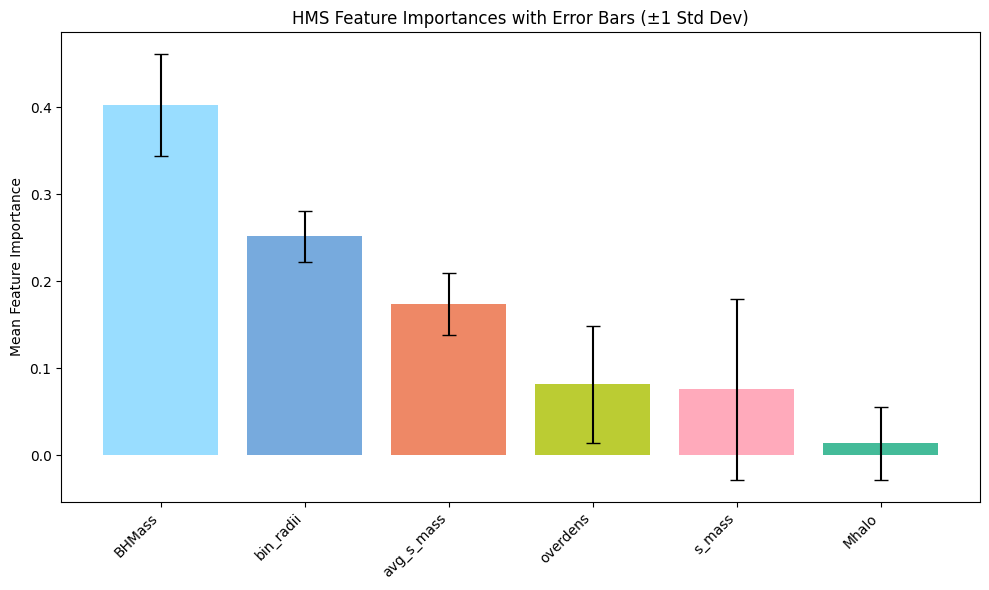

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
feature_colors = {
    'bin_radii': '#77AADD',
    'avg_s_mass': '#EE8866',
    's_mass': '#FFAABB',
    'BHMass': '#99DDFF',
    'Mhalo': '#44BB99',
    'overdens': '#BBCC33',
    'bulge': '#AAAA00',
    'BH_AGN': '#DDDDDD',
}

# importances + stds across 10 runs
importances_array = np.array(feature_importances_list)
importance_means = np.mean(importances_array, axis=0)
importance_stds = np.std(importances_array, axis=0)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Mean Importance': importance_means,
    'Std Dev': importance_stds
}).sort_values(by='Mean Importance', ascending=False)

print("\n=== Average Feature Importances ===")
print(importance_df)

colors = [feature_colors[feat] for feat in importance_df['Feature']]
# Plot
plt.figure(figsize=(10, 6))
plt.bar(importance_df['Feature'], importance_df['Mean Importance'], yerr=importance_df['Std Dev'], capsize=5, color=colors)
plt.xticks(rotation=45, ha='right')
plt.ylabel("Mean Feature Importance")
plt.title("HMS Feature Importances with Error Bars (±1 Std Dev)")
plt.tight_layout()
plt.show()

In [14]:
high_mass_satellite_df.corr()

,subID,bin_radii,avg_s_mass,avg_SFR,s_mass,BHMass,Mhalo,overdens,GrNr
subID,1.000000,0.086321,-0.170711,0.219320,-0.449632,-0.466979,-0.852118,-0.046053,0.823344
bin_radii,0.086321,1.000000,-0.874223,-0.220257,0.016649,0.002448,-0.080759,0.020776,0.058630
avg_s_mass,-0.170711,-0.874223,1.000000,0.200810,0.059657,0.081432,0.157396,0.001416,-0.116166
avg_SFR,0.219320,-0.220257,0.200810,1.000000,-0.129680,-0.165768,-0.163389,0.037313,0.219067
s_mass,-0.449632,0.016649,0.059657,-0.129680,1.000000,0.960461,0.393521,0.104974,-0.326213
BHMass,-0.466979,0.002448,0.081432,-0.165768,0.960461,1.000000,0.413942,0.165960,-0.336771
Mhalo,-0.852118,-0.080759,0.157396,-0.163389,0.393521,0.413942,1.000000,-0.001878,-0.492052
overdens,-0.046053,0.020776,0.001416,0.037313,0.104974,0.165960,-0.001878,1.000000,-0.045287
GrNr,0.823344,0.058630,-0.116166,0.219067,-0.326213,-0.336771,-0.492052,-0.045287,1.000000


In [15]:
import os
# Define your directory and file name
directory = os.path.join(OUT_ROOT, 'xg_regression_outputs')
filename = 'hms_xg_reg_halosplit.csv'
filepath = os.path.join(directory, filename)

# Create the directory if it doesn't exist
os.makedirs(directory, exist_ok=True)

# Save the DataFrame
importance_df.to_csv(filepath, index=False)

print(f'DataFrame saved to {filepath}')

DataFrame saved to ..\..\outputs\thresh_m2.6\xg_regression_outputs\hms_xg_reg_halosplit.csv


In [16]:
train_mean = round(np.mean(train_mses), 2)
test_mean = round(np.mean(test_mses), 2)

df = pd.DataFrame({
    'Train MSE': [train_mean],
    'Test MSE': [test_mean]
})

print(df)
import os
# Define your directory and file name
directory = os.path.join(OUT_ROOT, 'xg_regression_outputs')
filename = 'hms_xg_reg_mse_halosplit.csv'
filepath = os.path.join(directory, filename)

# Create the directory if it doesn't exist
os.makedirs(directory, exist_ok=True)

# Save the DataFrame
df.to_csv(filepath, index=False)

print(f'DataFrame saved to {filepath}')

   Train MSE  Test MSE
0       0.39      0.41
DataFrame saved to ..\..\outputs\thresh_m2.6\xg_regression_outputs\hms_xg_reg_mse_halosplit.csv
